# 复购与留存分析

Olist 复购率偏低（约 3%），分析重点：**谁在复购**、**复购间隔多长**、**复购用户与一次性用户的行为差异**。

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv',
                     parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date'])
customers = pd.read_csv('data/customers_clean.csv')

# 只取已送达订单，关联真实客户ID（customer_unique_id），按客户+时间排序
d = (orders[orders['order_status'] == 'delivered']
     .merge(customers[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id')
     .sort_values(['customer_unique_id', 'order_purchase_timestamp']))

n_orders = d.groupby('customer_unique_id')['order_id'].nunique()
rep_ids = set(n_orders[n_orders > 1].index)

d['is_rep'] = d['customer_unique_id'].isin(rep_ids)   # 客户是否复购用户
order_df = d.drop_duplicates('order_id')              # 订单级表（一单一行）

print(f"客户总数 {len(n_orders):,}，复购客户 {len(rep_ids):,}，复购率 {len(rep_ids)/len(n_orders):.1%}")

客户总数 93,358，复购客户 2,801，复购率 3.0%


## 首购后留存曲线

以全部客户为分母，看首购后 N 天内完成第二次购买的比例。

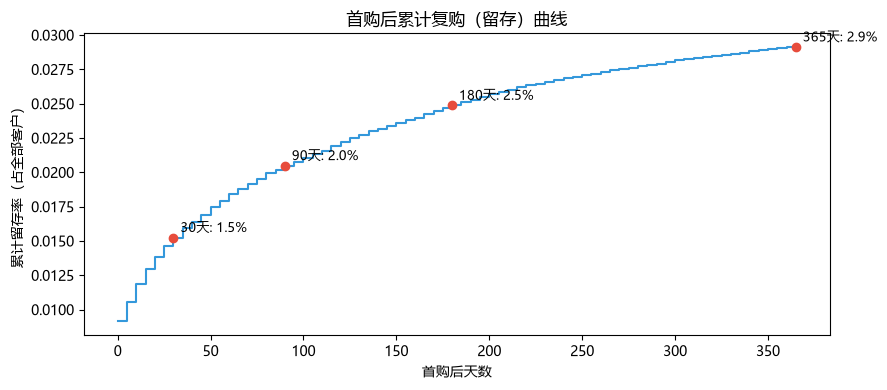

In [2]:
# 首次 -> 第二次购买的间隔（pandas3 下 nth(1)-min() 对齐异常，改用 cumcount）
d['ord_rank'] = d.groupby('customer_unique_id').cumcount()          # 0=首购, 1=第二次
first_t = d[d['ord_rank'] == 0].set_index('customer_unique_id')['order_purchase_timestamp']
second_t = d[d['ord_rank'] == 1].set_index('customer_unique_id')['order_purchase_timestamp']
gap_all = (second_t - first_t).dt.days.reindex(n_orders.index)      # 补齐全部客户，未复购=NaN
gap = gap_all.dropna()                                              # 仅复购客户，用于间隔分布

# 留存率分母 = 全部客户（NaN 视为未复购）
fig, ax = plt.subplots(figsize=(9, 4))
nds = np.arange(0, 366, 5)
ax.step(nds, [(gap_all <= nd).mean() for nd in nds], where='post', color='#3498db', label='累计留存率')
for nd in [30, 90, 180, 365]:
    v = (gap_all <= nd).mean()
    ax.scatter([nd], [v], color='#e74c3c', zorder=3)
    ax.annotate(f'{nd}天: {v:.1%}', (nd, v), textcoords='offset points', xytext=(5, 4), fontsize=9)
ax.set_xlabel('首购后天数'); ax.set_ylabel('累计留存率（占全部客户）')
ax.set_title('首购后累计复购（留存）曲线')
plt.tight_layout(); plt.show()

## 30 天唤醒漏斗

把留存曲线翻译成运营语言：首购后 30 天是唤醒窗口，窗口内未复购的客户大概率永久流失。

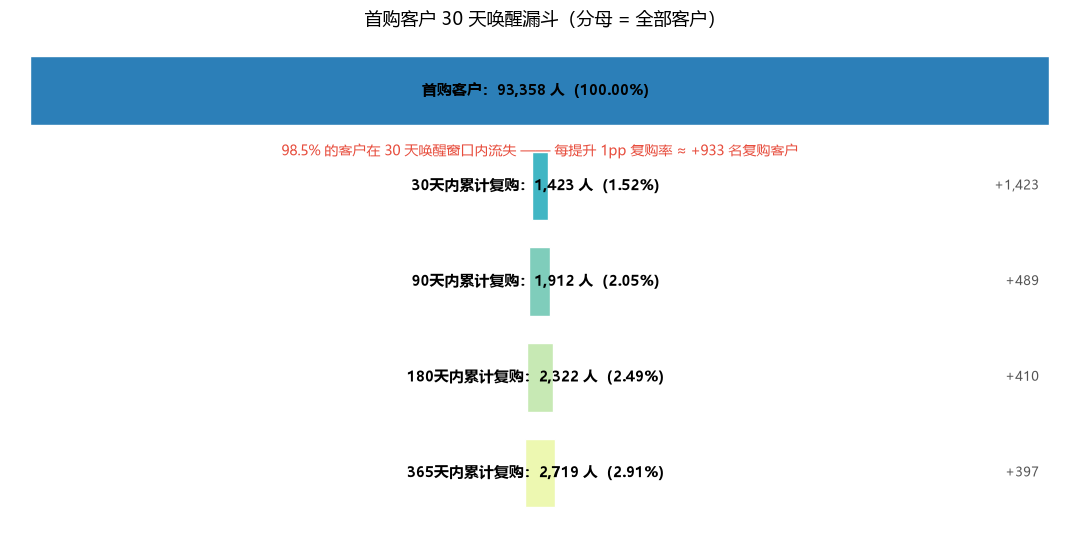

30 天唤醒窗口复购率: 1.52%（占全部客户）
全年累计复购率: 2.91%，窗口外（31~365天）仅补回 1.39%


In [3]:
n_all = len(n_orders)
ndays = [30, 90, 180, 365]
cum = [(gap_all <= nd).sum() for nd in ndays]      # 各时点累计复购人数
stages = ['首购客户'] + [f'{nd}天内累计复购' for nd in ndays]
counts = [n_all] + cum
pcts = [c / n_all for c in counts]

fig, ax = plt.subplots(figsize=(11, 5.5))
ypos = np.arange(len(stages))[::-1]
W = counts[0]
colors = ['#2c7fb8', '#41b6c4', '#7fcdbb', '#c7e9b4', '#edf8b1']
for i, (c, p) in enumerate(zip(counts, pcts)):
    ax.barh(ypos[i], c, left=(W - c) / 2, height=0.72,
            color=colors[i], edgecolor='white')
    ax.text(W / 2, ypos[i], f'{stages[i]}：{c:,} 人（{p:.2%}）',
            ha='center', va='center', fontsize=10.5, fontweight='bold')

# 右侧标注各阶段新增复购人数
for i in range(1, len(counts)):
    prev = counts[i - 1] if i > 1 else 0
    ax.text(W * 0.99, ypos[i], f'+{counts[i] - prev:,}',
            va='center', ha='right', fontsize=9, color='#555555')

ax.text(W / 2, ypos[0] - 0.68,
        f'{(1 - (gap_all <= 30).mean()):.1%} 的客户在 30 天唤醒窗口内流失 —— 每提升 1pp 复购率 ≈ +{n_all // 100:,} 名复购客户',
        ha='center', fontsize=10, color='#e74c3c')
ax.set_xlim(-W * 0.02, W * 1.03)
ax.axis('off')
ax.set_title('首购客户 30 天唤醒漏斗（分母 = 全部客户）', fontsize=13)
plt.tight_layout(); plt.show()

print(f"30 天唤醒窗口复购率: {(gap_all <= 30).mean():.2%}（占全部客户）")
print(f"全年累计复购率: {(gap_all <= 365).mean():.2%}，窗口外（31~365天）仅补回 {((gap_all <= 365).mean() - (gap_all <= 30).mean()):.2%}")

### 30 天唤醒漏斗的运营策略建议

漏斗告诉我们：资源应全部压在「首购后 0–30 天」，目标把窗口内复购率从 1.52% 推向 3%（≈ +1,400 名复购客户，按复购客户 LTV 309 估算，增量约 43 万雷亚尔）。

**1. 按时机分三段触达（基于复购间隔中位数 28 天）**

| 时间窗 | 动作 | 依据 |
|---|---|---|
| 第 0–7 天 | 物流安抚 + 晒单引导：送达确认、使用指南、邀请评分 | 差评 61% 来自物流，先把体验预期管住 |
| 第 8–15 天 | 品类教育：按首购品类推「搭配清单/使用技巧」内容 | 家居类强关联（床品+家具装饰共现最高） |
| 第 16–30 天 | 复购券直投：满减券（凑单免运费）+ 补货提醒 | 复购用户价格敏感（客单价更低、分期更多） |

**2. 按首购品类差异化**

- 家居日用类（bed_bath_table、housewares、furniture_decor）首购客户：推**补货/关联品**，这是复购主力品类，唤醒文案走「补货提醒」；
- 手表礼品、健康美容等低频品类首购客户：不硬推复购，改推**交叉品类券**（跨品类首单优惠），目标是促第二次「不同品类」购买；
- 未知品类（unknown/other）客户：推平台级新人回流券，做低成本兜底。

**3. 按客户分层控制预算**

- 高 M（首单金额 >P75）客户：窗口内人工/高权益触达（客服回访、大额券），他们 LTV 上限更高；
- 低 M 客户：仅自动化低成本渠道（邮件/App push），不投广告费；
- 挽留客户（R>365 天，40%）：**不投唤醒预算**，只保留系统自动邮件——本漏斗证明了错过 30 天窗口后补回仅 1.39%，付费召回是浪费。

**4. 验证机制**

- A/B 测试：30 天窗口内客户随机分对照组/触达组，核心指标 = 90 天累计复购率（基线 2.01%）；
- 逐步验证三个杠杆的独立贡献：补货提醒 vs 复购券 vs 凑单免运费；
- 每提升 1pp 的边际成本应 < 该批客户增量 LTV（+934 人 × 309 ≈ 29 万雷亚尔），作为投放上限的硬约束。

## 复购间隔分布

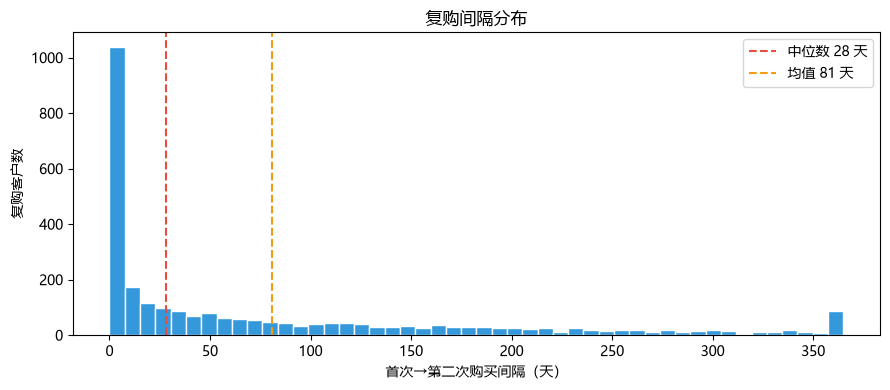

复购客户中：30 天内二次购买占 51%，90 天内占 68%


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(gap.clip(upper=365), bins=48, color='#3498db', edgecolor='white')
ax.axvline(gap.median(), color='#e74c3c', ls='--', label=f'中位数 {gap.median():.0f} 天')
ax.axvline(gap.mean(), color='#f39c12', ls='--', label=f'均值 {gap.mean():.0f} 天')
ax.set_xlabel('首次→第二次购买间隔（天）'); ax.set_ylabel('复购客户数')
ax.set_title('复购间隔分布'); ax.legend()
plt.tight_layout(); plt.show()

print(f"复购客户中：30 天内二次购买占 {(gap<=30).mean():.0%}，90 天内占 {(gap<=90).mean():.0%}")

## 复购用户 vs 一次性用户行为对比

          订单数   客单价均值   客单价中位  平均分期数  平均评分  平均送达天数     信用卡占比
is_rep                                                      
一次性用户   90557  160.76  105.39    2.9  4.15   12.11   0.77001
复购用户     5921  145.98  100.50    3.3  4.22   11.84  0.772674


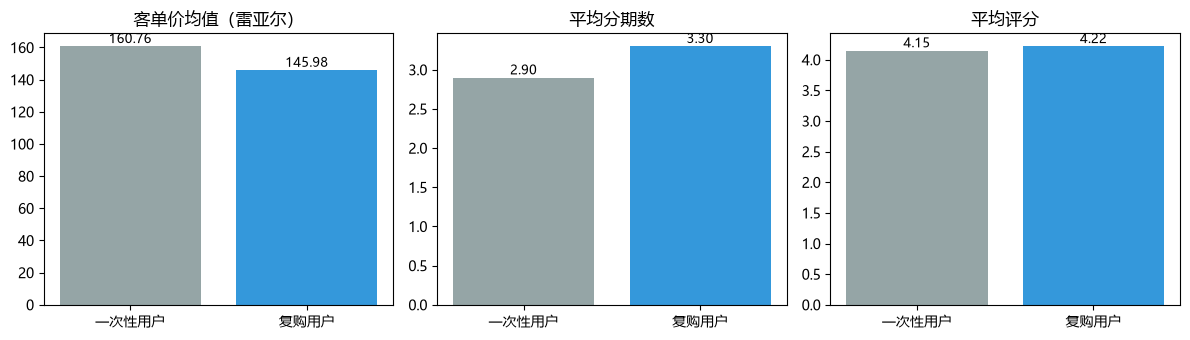

In [5]:
payments = pd.read_csv('data/order_payments_clean.csv')
reviews = pd.read_csv('data/order_reviews_clean.csv').drop_duplicates('order_id')

# 一单可能多笔支付，先按订单聚合
po = payments.groupby('order_id').agg(
    pay=('payment_value', 'sum'),
    inst=('payment_installments', 'max'),
    cc=('payment_type', lambda x: (x == 'credit_card').any()))

comp = order_df.copy()
comp['pay'] = comp['order_id'].map(po['pay'])
comp['inst'] = comp['order_id'].map(po['inst'])
comp['cc'] = comp['order_id'].map(po['cc'])
comp['rev'] = comp['order_id'].map(reviews.set_index('order_id')['review_score'])
comp['dl_days'] = (comp['order_delivered_customer_date'] - comp['order_purchase_timestamp']).dt.days

summary = comp.groupby('is_rep').agg(
    订单数=('order_id', 'nunique'),
    客单价均值=('pay', 'mean'), 客单价中位=('pay', 'median'),
    平均分期数=('inst', 'mean'), 平均评分=('rev', 'mean'),
    平均送达天数=('dl_days', 'mean'), 信用卡占比=('cc', 'mean'))\
  .rename(index={True: '复购用户', False: '一次性用户'}).round(2)
print(summary.to_string())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, title in zip(axes, ['客单价均值', '平均分期数', '平均评分'],
                          ['客单价均值（雷亚尔）', '平均分期数', '平均评分']):
    vals = [summary.loc['一次性用户', col], summary.loc['复购用户', col]]
    ax.bar(['一次性用户', '复购用户'], vals, color=['#95a5a6', '#3498db'])
    ax.set_title(title)
    for i, v in enumerate(vals):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

## 谁在复购：品类与地域

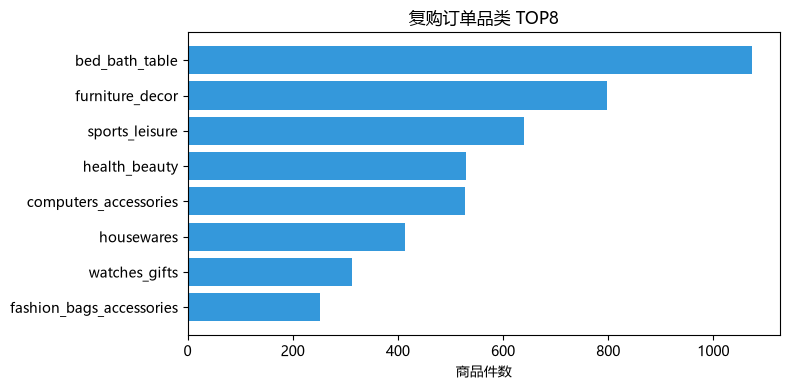

复购订单客户所在州 TOP5:
customer_state
SP    2575
RJ     827
MG     680
RS     336
PR     296


In [6]:
items = pd.read_csv('data/order_items_clean.csv')
products = pd.read_csv('data/products_clean.csv')
it = items.merge(products[['product_id', 'product_category_name_english']], on='product_id')

top_cat = (it[it['order_id'].isin(comp[comp['is_rep']]['order_id'])]
           ['product_category_name_english'].value_counts().head(8))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(top_cat.index[::-1], top_cat.values[::-1], color='#3498db')
ax.set_title('复购订单品类 TOP8'); ax.set_xlabel('商品件数')
plt.tight_layout(); plt.show()

print('复购订单客户所在州 TOP5:')
print(comp[comp['is_rep']]['customer_state'].value_counts().head(5).to_string())

## 复购与留存分析结论

### 1. 复购率与留存水平
- 93,358 名客户中仅 **2,801 人复购，复购率 3.0%**，平台以一次性交易为主。
- 首购后 **30 天留存 1.5%、90 天 2.0%、365 天 2.9%**；观察窗口有限（数据末期客户没有 365 天观察期），真实留存只会更低。

### 2. 复购集中在首月窗口
- 复购间隔**中位数仅 28 天，均值 81 天**（右偏分布，少数长间隔拉高均值）。
- 全部复购中 **51% 发生在首购后 30 天内，68% 发生在 90 天内** —— 首购后 30 天是唤醒黄金窗口，错过则大概率永久流失。

### 3. 谁在复购
- **地域**：复购订单客户集中在 SP（圣保罗）、RJ（里约）、MG（米纳斯）等东南部经济发达州。
- **品类**：bed_bath_table（床品餐桌）、furniture_decor（家具装饰）、sports_leisure（运动休闲）等**家居日用类**是复购主力，符合"消耗品/日用品驱动复购"的规律。

### 4. 复购用户与一次性用户的行为差异
- 复购用户**客单价反而略低**（均值 146 vs 161）：复购者是"高频小额"型，而非高消费人群。
- 复购用户**分期更多**（3.3 vs 2.9 期）、**评分略高**（4.22 vs 4.15）；送达时长（12 天）与支付方式（77% 信用卡）基本一致，物流和支付不是区分因素。
- **含义**：提升复购不靠提高客单价，而靠日用品类目运营 + 首购后 30 天内的精准触达（优惠券/补货提醒）。

## 业务解读

- 51% 的复购发生在首购后 30 天内——复购本质是「首月战役」，错过 30 天窗口的召回成本远高于首月内的预防成本。
- 复购品类集中在床品餐桌、家居日用等消耗性/补充性商品，说明**需求侧存在自然复购动机**，缺的是供给侧唤醒机制（补货提醒、复购券）。
- 复购用户客单价反而更低（146 vs 161），且分期更多——复购者是「熟悉平台后的精打细算型」，促销敏感，用折扣唤回比用新品唤回有效。
- 复购集中东南部发达州，与《运费与地理关系》互相印证：边远地区的复购障碍很可能同样是运费。

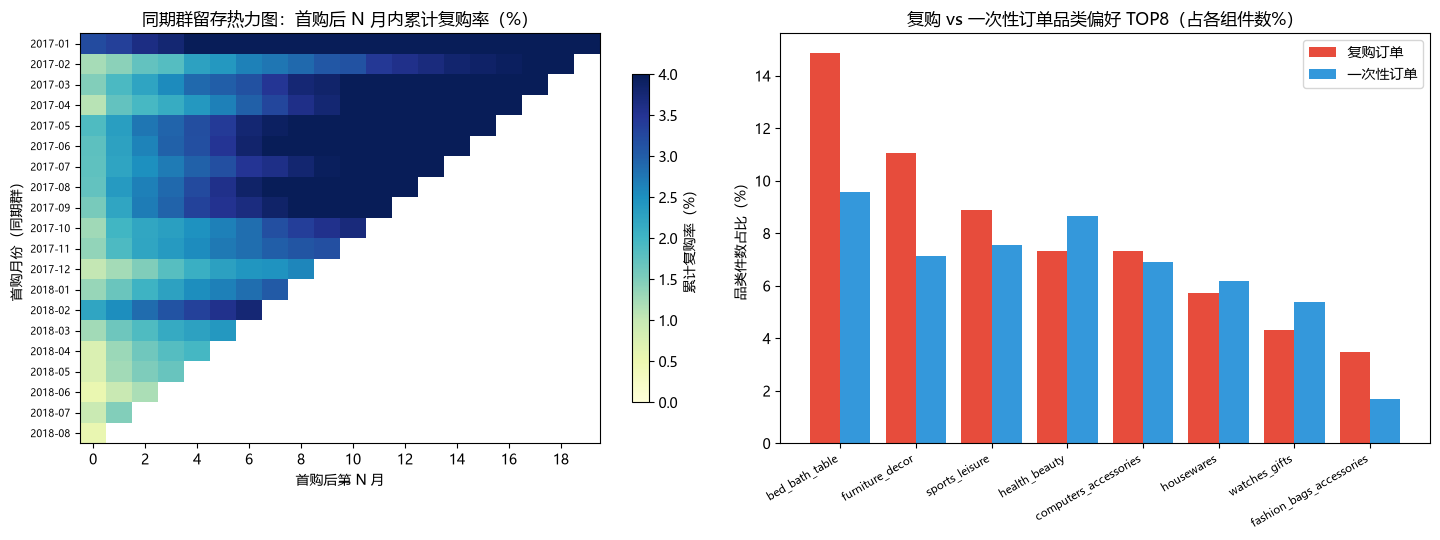

In [7]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# ① 同期群留存热力图：行=首购月份（2017-01 起），列=首购后第 N 月内累计复购率
first_m = d.loc[d['ord_rank'] == 0].set_index('customer_unique_id')['order_purchase_timestamp'].dt.to_period('M')
sec_m = d.loc[d['ord_rank'] == 1].set_index('customer_unique_id')['order_purchase_timestamp'].dt.to_period('M')
off_n = (sec_m - first_m).apply(lambda x: x.n if pd.notna(x) else np.nan)   # 复购距首购的月数
cohorts = first_m[first_m >= '2017-01']
data_end = pd.Period('2018-08', 'M')
cmonths = [str(p) for p in pd.period_range('2017-01', '2018-08', freq='M')]
n_off = len(cmonths)
mat = pd.DataFrame(np.nan, index=cmonths, columns=range(n_off))
for cm, grp in cohorts.groupby(cohorts):
    members = grp.index
    size = len(members)
    c_off = off_n.reindex(members)
    row = cmonths.index(str(cm))
    for n in range(n_off):
        if cm + n > data_end:      # 超出观察窗口的格子置空
            break
        mat.loc[str(cm), n] = (c_off <= n).mean() * 100

im = axes[0].imshow(np.ma.masked_invalid(mat.values), aspect='auto',
                    cmap='YlGnBu', vmin=0, vmax=4)
axes[0].set_yticks(range(len(cmonths)), cmonths, fontsize=7)
axes[0].set_xticks(range(0, n_off, 2), range(0, n_off, 2))
axes[0].set_xlabel('首购后第 N 月'); axes[0].set_ylabel('首购月份（同期群）')
axes[0].set_title('同期群留存热力图：首购后 N 月内累计复购率（%）')
plt.colorbar(im, ax=axes[0], shrink=.8, label='累计复购率（%）')

# ② 复购 vs 一次性订单的品类 TOP8 对比（占各组件数比例）
itx = it.merge(comp[['order_id', 'is_rep']], on='order_id')
cat_rep = itx.loc[itx['is_rep'], 'product_category_name_english'].value_counts(normalize=True) * 100
cat_one = itx.loc[~itx['is_rep'], 'product_category_name_english'].value_counts(normalize=True) * 100
top8 = cat_rep.head(8).index
xs2 = np.arange(len(top8))
axes[1].bar(xs2 - .2, cat_rep[top8].values, .4, label='复购订单', color='#e74c3c')
axes[1].bar(xs2 + .2, cat_one.reindex(top8).fillna(0).values, .4, label='一次性订单', color='#3498db')
axes[1].set_xticks(xs2, top8, rotation=30, ha='right', fontsize=8)
axes[1].set_ylabel('品类件数占比（%）')
axes[1].set_title('复购 vs 一次性订单品类偏好 TOP8（占各组件数%）')
axes[1].legend()

plt.tight_layout()
plt.show()